# 1 Molecular dynamics

## Randomness emerges from determinism

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
<strong>Note:</strong> This notebook contains the code for section 1.4 from the book 

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

<a id="randomness"></a>
## 1.4 Randomness

The book's Exercise 1.8 places a heavy tracer in a gas and studies its mean-square displacement (MSD). Here is a small extension using a **heavy tracer with the same Lennard–Jones size parameter** as the gas particles. Unlike the textbook's finite-radius tracer with shifted interaction distance, this simplified tracer only changes the mass; it is an explicitly different model and not a quantitative reproduction of Fig. 1.8.

For an unbounded two-dimensional diffusive trajectory, $\mathrm{MSD}(\tau) \simeq 4D \tau$ at sufficiently long lag. At short lag, inertia may produce a typical $\mathrm{MSD}(\tau) \propto \tau^2$ trend. 

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().parent / "01_modules"))

import molecular_dynamics as md
import md_visualize as vi

ModuleNotFoundError: No module named 'molecular_dynamics'

Let's start with a short simulation where we follow a particle slightly heavier than the others

In [ ]:
N = 100
box_length = 15.0
v0 = 1.5  # initial speed of the particles
m0 = 2.0  # initial mass of the disk
nsteps = 20000
dt = 0.001
nskip = 10
window_size = 360
particle_size = 0.5

tracer = vi.animate_gas(
    N, box_length, v0, m0, nsteps, dt, 
    nskip, window_size, particle_size
)

In [ ]:
tracer = np.asarray(tracer)
plt.figure(figsize=(3, 3))
plt.plot(tracer[:, 0], tracer[:, 1]); 
plt.xlim([0, box_length])
plt.ylim([0, box_length])
plt.xlabel("x / sigma"); 
plt.ylabel("y / sigma"); 
plt.gca().set_aspect("equal"); 
plt.gca().invert_yaxis(); 
plt.show()

NameError: name 'np' is not defined

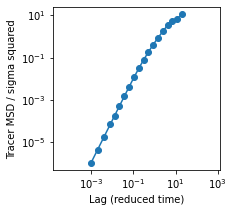

In [ ]:
lags = np.unique(np.geomspace(1, nsteps, 20).astype(int))
msd = md.mean_square_displacement(tracer, lags)

plt.figure(figsize=(3, 3))
plt.loglog(lags * dt, msd, "o-")
plt.xlabel("Lag (reduced time)"); 
plt.ylabel("Tracer MSD / sigma squared"); 
plt.axis("equal")
plt.show()

<a id="longer-simulation"></a>
### Simulating for a longer time

Let's try with a longer simulation, with no animation.
Note that, differently from above, the simulation calculates the interaction **only between the heavier particle and the remaining particles**, but **neglects the mutual interactions between the remaining particles**. This is done to have a faster calculations ($N$ instead of $N^2$)

In [ ]:
N = 10000
box_length = 20.0
v0 = 4.
m0 = 3.
nsteps = 80000
dt = 0.0002
nskip = 10000  # number of steps between text

print(f'Initializing positions for {N} particles...')
positions, velocities = md.initial_disk(N, box_length, speed=v0)
masses = np.ones(N); masses[0] = m0
tracer = []; tracer.append(positions[0].copy())
print(f'...done.')

for frame in range(nsteps // nskip):
    for step in range(nskip):
        # positions, velocities = md.step_particles(
        #     positions, velocities, dt, box_length, masses
        # )
        positions, velocities = md.step_brownian_disk(
            positions, velocities, dt, box_length, masses
        )
        tracer.append(positions[0].copy())
    print(f'[{(frame + 1) * nskip}/{nsteps}] completed.')


Initializing positions for 10000 particles...
...done.
[10000/80000] completed.
[20000/80000] completed.
[30000/80000] completed.
[40000/80000] completed.
[50000/80000] completed.
[60000/80000] completed.
[70000/80000] completed.
[80000/80000] completed.


Let's plot the particle's trajectory:

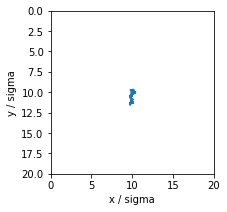

In [ ]:
tracer = np.asarray(tracer)
plt.figure(figsize=(3, 3))
plt.plot(tracer[:, 0], tracer[:, 1]); 
plt.xlim([0, box_length])
plt.ylim([0, box_length])
plt.xlabel("x / sigma"); 
plt.ylabel("y / sigma"); 
plt.gca().set_aspect("equal"); 
plt.gca().invert_yaxis(); 
plt.show()

We calculate the mean square displacement:

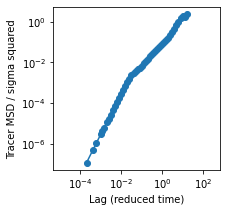

In [ ]:
lags = np.unique(np.geomspace(1, nsteps, 50).astype(int))
msd = md.mean_square_displacement(tracer, lags)

plt.figure(figsize=(3, 3))
plt.loglog(lags * dt, msd, "o-")
plt.xlabel("Lag (reduced time)"); 
plt.ylabel("Tracer MSD / sigma squared"); 
plt.axis("equal")
plt.show()

You can see the transition between ballistic and diffusive regimes.

## Further reading, problems, and challenges (textbook Sections 1.5–1.7)

The textbook's **Problem 1.2 (planetary orbit)** extends the same integration ideas to gravitational forces. **Problem 1.5 (two masses and a spring)** tests momentum and angular momentum. **Challenge 1.3 (Lennard–Jones gases, liquids, and solids)** asks how density and kinetic energy affect collective behavior. These are optional explorations, not formal homework.

**For study:** Explain why Euler energy drifts, why midpoint evaluation changes the algorithm, how a pairwise force loop scales with $N$, why an initially overlapping pair is dangerous, and how physical fluctuations differ from integration error.

**Reference:** Argun, Callegari & Volpe (2021), *Simulation of Complex Systems*, Chapter 1, Sections 1.1–1.7, Eqs. (1.1)–(1.11), Exercises 1.1–1.8.

<a id="questions"></a>

## Questions

Here you find the questions:
    
* [Q12: Rendomness](#q12)
    
* [Q13: A longer simulation](#q13)
    

<a id="q12"></a>**Question 12:** Randomness.

Refer to [randomness](#rendomness)
and check the [module molecular_dynamics.py](../01_modules/molecular_dynamics.py)

[Go back to questions](#questions)

Write the outcome of:


a. np.geomspace(1, 1000, 4)


b. np.geomspace(1, 1000, 4).astype(int) 


c. np.geomspace(1, 17, 2)


d. np.geomspace(1, 2, 5).astype(int) 


e. np.unique(np.geomspace(1, 2, 5).astype(int))


In *mean_square_displacement*, refer to the line:
```python
MSD = np.array(
        [np.mean(np.sum((trajectory[lag:] 
                         - trajectory[:-lag])**2, axis=1)) 
         for lag in lags]
```

f. What is a possible value for "lag"?


g. Assume "lag" is 3 and trajectory.shape is (6, 2).
Write  a.shape when:
```python
a = trajectory[lag:] - trajectory[:-lag]
```

h. Assume "lag" is 3 and trajectory.shape is (100, 2).
Write a.shape when:
```python
a = trajectory[lag:] - trajectory[:-lag]
```

i. Assume "lag" is 3 and trajectory.shape is (100, 2).
Write b.shape when:
```python
b = np.sum((trajectory[lag:] - trajectory[:-lag])**2, axis=1)
```

j. Assume "lag" is 3 and trajectory.shape is (100, 2).
Write c.shape when:
```python
c = np.mean(np.sum((trajectory[lag:] - trajectory[:-lag])**2, axis=1)) 
```

k. What is msd.shape, if msd = md.mean_square_displacement(tracer, lags)?


<a id="q13"></a>**Question 13:** A longer simulation for the Brownian disk.

Refer to the [longer simulation](#longer-simulation) without animation.
   
[Go back to questions](#questions)

a. Run the simulation with:
```python
v0 = 4.
m0 = 0.5
```
What happens to the MSD plot?


b. Run the simulation with:
```python
v0 = 1.
m0 = 0.5
```
What happens to the MSD plot?


c. Run the simulation with:
```python
v0 = 5
m0 = 1
```
What happens to the MSD plot?

